In [1]:
import os

import pandas as pd
import psycopg
import mlflow
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, 
    SplineTransformer, 
    QuantileTransformer, 
    RobustScaler,
    PolynomialFeatures,
    KBinsDiscretizer,
)

from dotenv import load_dotenv

load_dotenv()

TABLE_NAME = "users_churn"

TRACKING_SERVER_HOST = "127.0.0.1"
TRACKING_SERVER_PORT = 5000

mlflow.set_tracking_uri(f"http://{TRACKING_SERVER_HOST}:{TRACKING_SERVER_PORT}")
mlflow.set_registry_uri(f"http://{TRACKING_SERVER_HOST}:{TRACKING_SERVER_PORT}")

EXPERIMENT_NAME = "Feature_selection_methods_lession_10"
RUN_NAME = "eature_selection"
REGISTRY_MODEL_NAME = "feature_selection_methods_lession_10_model"

ASSETS_DIR = "assets"

os.makedirs(ASSETS_DIR, exist_ok=True)

pd.options.display.max_columns = 100
pd.options.display.max_rows = 64

/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/pydantic/_internal/_config.py:408: UserWarning: Valid config keys have changed in V2:
* 'schema_extra' has been renamed to 'json_schema_extra'
  warnings.warn(message, UserWarning)


In [2]:
connection = {"sslmode": "require", "target_session_attrs": "read-write"}
postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD"),
    "sslmode": "disable"
}

connection.update(postgres_credentials)

with psycopg.connect(**connection) as conn:

    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM destination.{TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]

df = pd.DataFrame(data, columns=columns)

df.head(2)

,id,customer_id,begin_date,end_date,type,paperless_billing,payment_method,monthly_charges,total_charges,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,gender,senior_citizen,partner,dependents,multiple_lines,target
0,4,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,DSL,Yes,No,Yes,No,No,No,Male,0,No,No,No,0
1,5,3668-QPYBK,2019-11-01,2020-01-01,Month-to-month,Yes,Mailed check,53.85,108.15,DSL,Yes,Yes,No,No,No,No,Male,0,No,No,No,1


In [3]:
from sklearn.ensemble import RandomForestClassifier
from mlxtend.feature_selection import SequentialFeatureSelector

# 1. Подготовка данных (заполнение пропусков и кодирование категорий, если в df есть строковые столбцы)
df_prep = df.drop(columns=["id", "customer_id", "begin_date", "end_date"], errors="ignore").copy()
df_prep["total_charges"] = df_prep["total_charges"].fillna(0)

# Кодируем категориальные столбцы в числовые индикаторы
cat_cols = df_prep.select_dtypes(include=["object", "category"]).columns.tolist()
if cat_cols:
    df_prep = pd.get_dummies(df_prep, columns=cat_cols, drop_first=True)

X = df_prep.drop(columns=["target"])
y = df_prep["target"]

# 2. Инициализация оценщика (случайный лес с 300 деревьями)
estimator = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

# 3. Инициализация SFS и SBS
sfs = SequentialFeatureSelector(
    estimator=estimator,
    k_features=10,
    forward=True,
    floating=False,
    scoring="roc_auc",
    cv=4,
    n_jobs=-1
)

sbs = SequentialFeatureSelector(
    estimator=estimator,
    k_features=10,
    forward=False,
    floating=False,
    scoring="roc_auc",
    cv=4,
    n_jobs=-1
)

# 4. Запуск отбора признаков
sfs = sfs.fit(X, y)
sbs = sbs.fit(X, y)

# 5. Сохранение имен отобранных признаков
top_sfs = list(sfs.k_feature_names_)
top_sbs = list(sbs.k_feature_names_)

print('\nSequential Forward Selection (k=10)')
print('CV Score:')
print(sfs.k_score_)

print('\nSequential Backward Selection')
print('CV Score:')
print(sbs.k_score_)

/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(
/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(
/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(
/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(
/home/mle-user/p


Sequential Forward Selection (k=10)
CV Score:
0.8006879696301793

Sequential Backward Selection
CV Score:
0.8141475492197323


In [4]:
sfs_df = pd.DataFrame.from_dict(sfs.get_metric_dict()).T
sbs_df = pd.DataFrame.from_dict(sbs.get_metric_dict()).T

In [6]:
sfs_df.to_csv(f"{ASSETS_DIR}/sfs.csv")
sbs_df.to_csv(f"{ASSETS_DIR}/sbs.csv") 

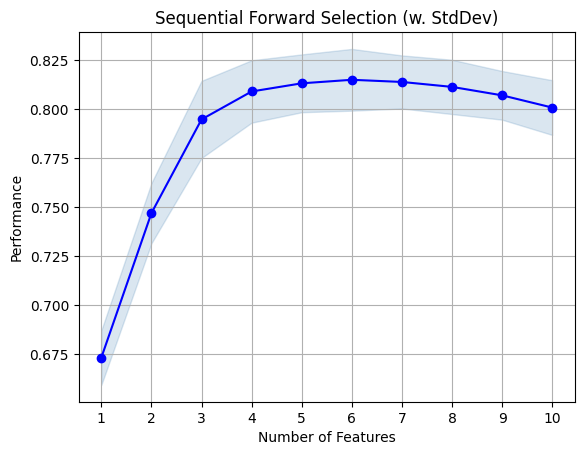

<Figure size 640x480 with 0 Axes>

In [8]:
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

fig = plot_sfs(sfs.get_metric_dict(), kind='std_dev')

plt.title('Sequential Forward Selection (w. StdDev)')
plt.grid()
plt.show()

plt.savefig(f"{ASSETS_DIR}/sfs.png")

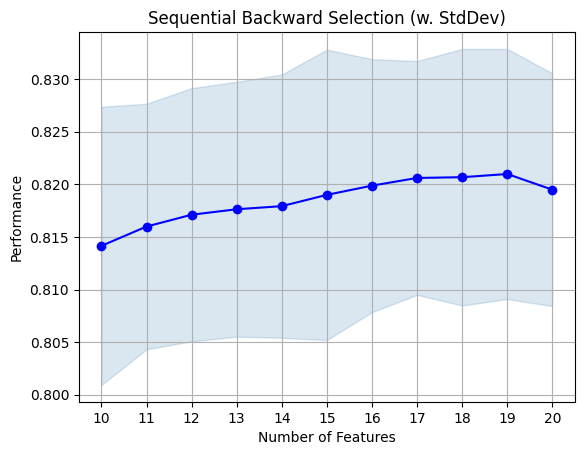

<Figure size 640x480 with 0 Axes>

In [9]:
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

fig = plot_sfs(sbs.get_metric_dict(), kind='std_dev')

plt.title('Sequential Backward Selection (w. StdDev)')
plt.grid()
plt.show()

plt.savefig(f"{ASSETS_DIR}/sbs.png")

In [10]:
interc_features = list(set(top_sbs) & set(top_sfs))
union_features = list(set(top_sbs) | set(top_sfs))

In [12]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    experiment_id = mlflow.create_experiment(EXPERIMENT_NAME)
else:
    experiment_id = experiment.experiment_id

with mlflow.start_run(run_name=f"{RUN_NAME}_intersection_and_union", experiment_id=experiment_id) as run:
    run_id = run.info.run_id
   
    mlflow.log_artifacts(ASSETS_DIR)

In [17]:
import mlflow
from mlflow.tracking import MlflowClient
from catboost import CatBoostClassifier  # или RandomForestClassifier(n_estimators=300, random_state=42)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, log_loss

# Функция для обучения, оценки и логирования модели в нужный эксперимент
def train_and_log_model(feature_list, exp_name, run_name, reg_model_name):
    # Разбиваем подготовленный датафрейм X, y (из Задания 1) на train и test
    X_tr, X_te, y_tr, y_te = train_test_split(
        X[feature_list], y, test_size=0.2, random_state=42, stratify=y
    )
    
    model = CatBoostClassifier(random_state=42, verbose=0)
    model.fit(X_tr, y_tr)
    
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    
    metrics = {
        "roc_auc": roc_auc_score(y_te, y_proba),
        "f1": f1_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred),
        "recall": recall_score(y_te, y_pred),
        "logloss": log_loss(y_te, y_proba),
    }
    print(f"Метрики для эксперимента '{exp_name}' ({len(feature_list)} признаков):", metrics)
    
    # Получаем или создаем эксперимент
    experiment = mlflow.get_experiment_by_name(exp_name)
    exp_id = experiment.experiment_id if experiment else mlflow.create_experiment(exp_name)
    
    with mlflow.start_run(run_name=run_name, experiment_id=exp_id) as run:
        current_run_id = run.info.run_id
        
        mlflow.log_metrics(metrics)
        mlflow.log_params(model.get_params())
        mlflow.log_param("features_count", len(feature_list))
        
        mlflow.catboost.log_model(
            cb_model=model,
            artifact_path="models",
            registered_model_name=reg_model_name,
            input_example=X_te.iloc[:5]
        )
        
    # Получаем номер зарегистрированной версии через MlflowClient
    client = MlflowClient()
    versions = client.search_model_versions(f"name='{reg_model_name}' and run_id='{current_run_id}'")
    version_id = int(versions[0].version)
    
    return current_run_id, version_id

# 1. Обучаем и регистрируем модель на пересечении признаков с run_name="feature_selection_intersection"
run_id_interc_new, version_interc = train_and_log_model(
    feature_list=interc_features,
    exp_name="feature_selection_intersection",
    run_name="feature_selection_intersection",
    reg_model_name=REGISTRY_MODEL_NAME
)

# 2. Обучаем и регистрируем модель на объединении признаков с run_name="feature_selection_union"
run_id_union_new, version_union = train_and_log_model(
    feature_list=union_features,
    exp_name="feature_selection_union",
    run_name="feature_selection_union",
    reg_model_name=REGISTRY_MODEL_NAME
)

print(f"registred_model_name = '{REGISTRY_MODEL_NAME}'")
print(f"model_version_id_interc = {version_interc}")
print('model_registred_name_interc = "feature_selection_intersection"')
print('model_registred_name_union = "feature_selection_union"')
print(f"model_version_id_union = {version_union}")
print('run_name_union = "feature_selection_union"')
print('run_name_interc = "feature_selection_intersection"')
print(f'run_id_interc = "{run_id_interc_new}"')
print(f'run_id_union = "{run_id_union_new}"')

Метрики для эксперимента 'feature_selection_intersection' (6 признаков): {'roc_auc': 0.8143984603063885, 'f1': 0.45500848896434637, 'precision': 0.6232558139534884, 'recall': 0.3582887700534759, 'logloss': 0.45350057193002297}


/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/mlflow/models/signature.py:344: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  output_schema = _infer_schema(prediction)
Registered model 'feature_selection_methods_lession_10_model' already exists. Creating a new version of this model...
2026/11/20 05:09:25 INFO mlflow.tracking._model_registry.client: Wai

Метрики для эксперимента 'feature_selection_union' (14 признаков): {'roc_auc': 0.8362138004081738, 'f1': 0.5731523378582202, 'precision': 0.657439446366782, 'recall': 0.5080213903743316, 'logloss': 0.42938563184127815}


/home/mle-user/projects/mle-mlflow/.venv/lib/python3.10/site-packages/mlflow/models/signature.py:344: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  output_schema = _infer_schema(prediction)
Registered model 'feature_selection_methods_lession_10_model' already exists. Creating a new version of this model...
2026/11/20 05:09:29 INFO mlflow.tracking._model_registry.client: Wai

registred_model_name = 'feature_selection_methods_lession_10_model'
model_version_id_interc = 7
model_registred_name_interc = "feature_selection_intersection"
model_registred_name_union = "feature_selection_union"
model_version_id_union = 8
run_name_union = "feature_selection_union"
run_name_interc = "feature_selection_intersection"
run_id_interc = "d4d671d7da2f46aa9beb39f9cc873146"
run_id_union = "adc6561b13ad4cfdaf30cadd916d786f"


Created version '8' of model 'feature_selection_methods_lession_10_model'.
